# 🧪 LAB: Manual MLPs for Classification and Regression

In this lab, you will use `PyTorch` to implement manually a multi-layer perceptron (MLP) for three different tasks: binary classification, multi-class classification and regression. 

## General instructions to complete in ALL three tasks:

1. ***IMPLEMENTATION***:
   
Implement a separate class for each task:

  - `BinaryMLP` for the binary classification task  
  - `MultiClassMLP` for the multi-class classification task  
  - `RegressionMLP` for the regression task

   Each class must include the following methods:

  - `__init__` for initializing 1 or 2 hidden layers. (*Help*: having a second hidden layer only means the need of having a extra set of weights and intercept). 
  - `forward` to transfer information from the input to the output layer. (*Help*: make sure that information passes through a second hidden layer if there is one).
  - `cost` computing the cost.
  - `fit` for training, using the gradients to manually update the parameters of the model. **Use stochastic gradient descent to update your weights**. *N.B.* You may probably reuse much of the code we used in this week tutorial already. 
  - `predict` to convert the information at the output layer into the required output.

2. ***DATA PREPARATION***

For each task, you will be provided with a toy dataset. For each dataset:

  - Split into training and holdout sets (use an 80/20 split)
  - Standardize the features properly, avoiding data leakage
  - Convert all data into `PyTorch` Tensors for compatibility

3. ***MODEL TRAINING AND EVALUATION***

Instantiate the model for each task and train it under different hyperparameter configurations. In each case, record the performance on **both** the training and holdout sets using the appropriate metric for the task (accuracy, MSE, etc.). You should explore the following configurations:

  - One hidden layer, varying the number of hidden units (use ReLU as their activation function)
  - Same number of hidden units across one or two hidden layers (use ReLU as their activation function)
  - Repeat the above setups using Tanh activation instead of ReLU

Present your results in a compact way (e.g., a summary table, a data frame etc).

**NOTE**: When training your model, use a fixed learning rate of your choice (e.g., 0.01 is a reasonable starting point) and a reasonably large number of  epochs (e.g., 100–200) based on how training and holdout performance evolve.

4. ***REFLECTION AND DISCUSSION***

Reflect on the impact of the different hyperparameter settings:

- How does the number of hidden units affect performance?
- What changes when using two layers instead of one?
- How does the activation function (ReLU vs. Tanh) influence results?

Please elaborate your answers.

---

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

**Ideally, each group member should be responsible for one of the separate tasks.** BUT, everyone should help each other along the way, both reviewing and refining results and discussion.

---

In total, this lab assignment will be worth **100 points**.

--- 
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.


NAME(s) = "Kavan W., Michelle J., Max G."

## 1. Pre-implementation Group Discussion (15 points)

Discuss and agree on:

- What cost function should be used for each of the below task.
- What changes are needed in the output layer for each of these tasks. In particular, consider the number of units and the activation function.
- Why it is important to standardize the data before training each model.
- How you could detect overfitting when training your models.

What cost function should be used for each of the below task.
- Binary - Binary Cross-Entropy Loss
- Multi-class - Categorical Cross-Entropy Loss
- Regression - Mean Squared Error

What changes are needed in the output layer for each of these tasks. In particular, consider the number of units and the activation function.

- Binary - Number of outputs is 1, a single value. The activation function is a sigmoid activation function which turns any number into a value between 0 and 1, which is the probability of class 1.
- Multi-class - The number of units is dependent on the number of classes, with one output per class. The activation function is softmax, which turns all the k scores into probabilities that all sum up to 1.
- Regression - The number of units is 1 and there is no activation function.


Why it is important to standardize the data before training each model.
- It is important to standardize the data before training each model so that they are on a comparable scale. This helps gradient descent train better and prevents larger-scale features from skewing training. The scaler should be fitted on only the training data, then it is used to transform both the training and holdout data, which helps avoid data leakage.

How you could detect overfitting when training your models.
- We can detect overfitting when training our models by comparing the training and holdout performance during training. If training loss continues to decrease while holdout loss increases, then there is overfitting. Another sign is that, in classification, the training accuracy improves while holdout accuracy stays the same or declines.

## 2. Binary Classification (25 points)

Use the dataset below to complete points 1 to 4 in the general instructions for this task.

Use as many cells as needed.

In [ ]:
from sklearn.datasets import make_moons

X, y = make_moons(n_samples=1000, noise=0.2, random_state=42)

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import torch
import torch.nn as nn
import pandas as pd

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)
y_train = torch.tensor(y_train.reshape(-1, 1), dtype=torch.float32)
y_test = torch.tensor(y_test.reshape(-1, 1), dtype=torch.float32)

In [ ]:
class BinaryMLP:
    def __init__(self, input_dim, hidden_dim, num_layers=1, activation="relu"):
        self.num_layers = num_layers
        self.activation = activation.lower()

        self.W1 = nn.Parameter(torch.randn(input_dim, hidden_dim) * 0.1)
        self.b1 = nn.Parameter(torch.zeros(1, hidden_dim))

        if num_layers == 2:
            self.W2 = nn.Parameter(torch.randn(hidden_dim, hidden_dim) * 0.1)
            self.b2 = nn.Parameter(torch.zeros(1, hidden_dim))
        else:
            self.W2 = None
            self.b2 = None

        self.W_out = nn.Parameter(torch.randn(hidden_dim, 1) * 0.1)
        self.b_out = nn.Parameter(torch.zeros(1, 1))

    def forward(self, X):
        z1 = torch.matmul(X, self.W1) + self.b1

        if self.activation == "relu":
            a1 = torch.clamp(z1, min=0)
        else:
            a1 = torch.tanh(z1)

        if self.num_layers == 2:
            z2 = torch.matmul(a1, self.W2) + self.b2
            if self.activation == "relu":
                a2 = torch.clamp(z2, min=0)
            else:
                a2 = torch.tanh(z2)
            z_out = torch.matmul(a2, self.W_out) + self.b_out
        else:
            z_out = torch.matmul(a1, self.W_out) + self.b_out

        return torch.sigmoid(z_out)

    def cost(self, y_pred, y_true):
        # Binary cross entropy loss
        return -torch.mean(
            y_true * torch.log(y_pred + 1e-7)
            + (1.0 - y_true) * torch.log(1.0 - y_pred + 1e-7)
        )

    def fit(self, X, y, epochs=200, lr=0.01):
        params = [self.W1, self.b1, self.W_out, self.b_out]

        if self.num_layers == 2:
            params.extend([self.W2, self.b2])

        for epoch in range(epochs):
            for p in params:
                if p.grad is not None:
                    p.grad.zero_()

            predictions = self.forward(X)
            loss = self.cost(predictions, y)
            loss.backward()

            with torch.no_grad():
                for p in params:
                    p -= lr * p.grad

    def predict(self, X):
        with torch.no_grad():
            probs = self.forward(X)
            return (probs >= 0.5).float()

In [ ]:
configs = [
    (8, 1),
    (16, 1),
    (32, 1),
    (16, 2)
]

activations = ["ReLU", "Tanh"]
results = []

# Train and evaluate each configuration
for activation in activations:
    for hidden_units, num_layers in configs:
        torch.manual_seed(42)

        model = BinaryMLP(
            input_dim=2,
            hidden_dim=hidden_units,
            num_layers=num_layers,
            activation=activation
        )

        # Train the model using manual SGD
        model.fit(X_train, y_train, epochs=200, lr=0.01)

        # Evaluate training and holdout
        with torch.no_grad():
            train_predictions = model.forward(X_train)
            test_predictions = model.forward(X_test)
            train_loss = model.cost(train_predictions, y_train).item()
            test_loss = model.cost(test_predictions, y_test).item()

            train_accuracy = (
                (model.predict(X_train) == y_train)
            ).float().mean().item()

            test_accuracy = (
                (model.predict(X_test) == y_test)
            ).float().mean().item()

        results.append({
            "Activation": activation,
            "Hidden Layers": num_layers,
            "Hidden Units": hidden_units,
            "Train Accuracy": round(train_accuracy, 4),
            "Holdout Accuracy": round(test_accuracy, 4),
            "Train Loss": round(train_loss, 4),
            "Holdout Loss": round(test_loss, 4)
        })

results_df = pd.DataFrame(results)
results_df

In [ ]:
results_df.sort_values("Holdout Accuracy", ascending=False)

## 2. Multi-Class Classification (25 points)

Use the dataset below to complete points 1 to 4 in the general instructions for this task.

Use as many cells as needed.

---
**NOTE**: This will likely be the most challenging exercise. To help you, here are some pointers:

 - The **output (last) layer** should have as many units as there are classes in your data.  

 - The **activation function of the output layer must be softmax**, not sigmoid. Softmax ensures that all output values are between 0 and 1 and sum to 1, so they can be interpreted as probabilities across the different classes. (*Help*: you may want to look into `torch.nn.functional` to find its implementation...)

 - For a multi-class problem, your target variable `y` should be **one-hot encoded**. For example:  
   - Label = 0 → [1, 0, 0]  
   - Label = 1 → [0, 1, 0]  
   - Label = 2 → [0, 0, 1]  
   You can easily achieve this with `OneHotEncoder` from `sklearn.preprocessing`.  

 - The **predicted class** corresponds to the unit with the highest probability.  
   Example:  
   - `[0.1, 0.3, 0.6] → class 2`  
   - `[0.6, 0.2, 0.2] → class 0`  

 - For this exercise, you need to **implement the categorical cross-entropy loss** (an extension of binary cross-entropy to multiple classes). It is defined as:  

   $$\sum_{c=1}^{l} y_{o,c}\,\log(p_{o,c}),$$

   where $l$ is the number of classes, $y_{o,c}$ is the one-hot encoded label for observation $o$, and $p_{o,c}$ is the predicted probability for class $c$ (after applying softmax). The log is the natural logarithm.

---

In [2]:
from sklearn.datasets import make_classification

X, y = make_classification(n_samples=1000, n_classes=3, 
                           n_clusters_per_class=1, 
                           n_features=2, n_informative=2, n_redundant=0, random_state=1234, flip_y=0.15)

In [5]:
import torch
from sklearn.model_selection import train_test_split

X_train_mc, X_holdout_mc, y_train_mc, y_holdout_mc =  train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"X_train shape:{X_train_mc.shape}")
print(f"X_holdout shape:{X_holdout_mc.shape}")
print(f"y_train shape: {y_train_mc.shape}")
print(f"y_holdout shape: {y_holdout_mc.shape}")

X_train shape:(800, 2)
X_holdout shape:(200, 2)
y_train shape: (800,)
y_holdout shape: (200,)


In [6]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder

scaler_mc = StandardScaler()

X_train_mc = scaler_mc.fit_transform(X_train_mc)
X_holdout_mc = scaler_mc.transform(X_holdout_mc)

encoder_mc = OneHotEncoder(sparse_output=False)
y_train_oh = encoder_mc.fit_transform(y_train_mc.reshape(-1,1))
y_holdout_oh = encoder_mc.transform(y_holdout_mc.reshape(-1,1))

X_train_mc = torch.tensor(X_train_mc, dtype=torch.float32)
X_holdout_mc = torch.tensor(X_holdout_mc, dtype=torch.float32)
y_train_oh = torch.tensor(y_train_oh, dtype=torch.float32)
y_holdout_oh = torch.tensor(y_holdout_oh, dtype=torch.float32)



In [20]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class MultiClassMLP(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim=3, num_layers=1, activation="relu"):
        super().__init__()
        self.num_layers = num_layers
        self.activation = activation.lower()

        # Hidden layer 1
        self.W1 = nn.Parameter(torch.randn(input_dim, hidden_dim) * 0.1)
        self.b1 = nn.Parameter(torch.zeros(1, hidden_dim))

        # Hidden layer 2 (optional)
        if num_layers == 2:
            self.W2 = nn.Parameter(torch.randn(hidden_dim, hidden_dim) * 0.1)
            self.b2 = nn.Parameter(torch.zeros(1, hidden_dim))

        # Output layer: one unit per class
        self.W_out = nn.Parameter(torch.randn(hidden_dim, output_dim) * 0.1)
        self.b_out = nn.Parameter(torch.zeros(1, output_dim))

    def _activate(self, z):
        if self.activation == 'relu':
            return F.relu(z)
        return torch.tanh(z)

    def forward(self, X):
        h = self._activate(torch.matmul(X, self.W1) +self.b1)

        if self.num_layers == 2:
            h = self._activate(torch.matmul(h,self.W2) + self.b2)

        z_out = torch.matmul(h, self.W_out) + self.b_out
        return F.softmax(z_out, dim=1)

    def cost(self, y_pred, y_true):
        eps = torch.finfo(y_pred.dtype).eps
        y_pred = torch.clamp(y_pred, eps, 1 - eps)
        return -torch.mean(torch.sum(y_true * torch.log(y_pred), dim=1))

    def fit(self, X, y, epochs=200, lr=0.01, batch_size=1, X_val=None, y_val=None):
        self.train_costs, self.val_costs = [], []

        for epoch in range(epochs):
            randperm = torch.randperm(X.shape[0])

            for start in range(0, X.shape[0], batch_size):
                idx = randperm[start:start + batch_size]
                x_batch, y_batch = X[idx], y[idx]

                probs = self(x_batch)
                cost = self.cost(probs, y_batch)

                cost.backward()

                with torch.no_grad():
                    for p in self.parameters():
                        p -= lr * p.grad
                        p.grad.zero_()

            with torch.no_grad():
                self.train_costs.append(self.cost(self(X), y).item())
                if X_val is not None:
                    self.val_costs.append(self.cost(self(X_val), y_val).item())

        return self

    def predict(self, X):
        with torch.no_grad():
            probs = self(X)
            return probs.argmax(dim=1)
 

Train accuracy: 0.8063 | Holdout accuracy: 0.8350


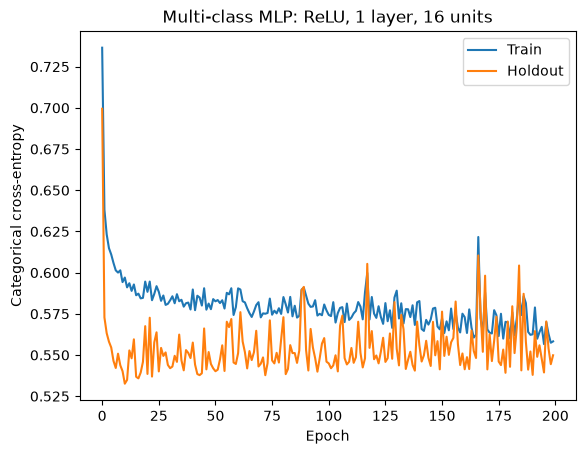

In [21]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

torch.manual_seed(42)
sanity_model = MultiClassMLP(input_dim=2, hidden_dim=16, num_layers=1, activation="relu")
sanity_model.fit(X_train_mc, y_train_oh, epochs=200, lr=0.01,
                 X_val=X_holdout_mc, y_val=y_holdout_oh)

train_acc = accuracy_score(y_train_mc, sanity_model.predict(X_train_mc).numpy())
holdout_acc = accuracy_score(y_holdout_mc, sanity_model.predict(X_holdout_mc).numpy())
print(f"Train accuracy: {train_acc:.4f} | Holdout accuracy: {holdout_acc:.4f}")

plt.plot(sanity_model.train_costs, label="Train")
plt.plot(sanity_model.val_costs, label="Holdout")
plt.xlabel("Epoch")
plt.ylabel("Categorical cross-entropy")
plt.title("Multi-class MLP: ReLU, 1 layer, 16 units")
plt.legend()
plt.show()

In [22]:
import pandas as pd

mc_results = []

for activation in ["relu", "tanh"]:
    for hidden_units in [8, 16, 32]:
        for num_layers in [1, 2]:
            torch.manual_seed(42)

            model = MultiClassMLP(
                input_dim=2,
                hidden_dim=hidden_units,
                num_layers=num_layers,
                activation=activation
            )

            # Train with manual SGD
            model.fit(X_train_mc, y_train_oh, epochs=200, lr=0.01)

            # Evaluate on train and holdout
            with torch.no_grad():
                train_loss = model.cost(model(X_train_mc), y_train_oh).item()
                holdout_loss = model.cost(model(X_holdout_mc), y_holdout_oh).item()

            train_acc = accuracy_score(y_train_mc, model.predict(X_train_mc).numpy())
            holdout_acc = accuracy_score(y_holdout_mc, model.predict(X_holdout_mc).numpy())

            mc_results.append({
                "Activation": activation,
                "Hidden Units": hidden_units,
                "Hidden Layers": num_layers,
                "Train Accuracy": round(train_acc, 4),
                "Holdout Accuracy": round(holdout_acc, 4),
                "Train Loss": round(train_loss, 4),
                "Holdout Loss": round(holdout_loss, 4)
            })

mc_results_df = pd.DataFrame(mc_results)
mc_results_df

,Activation,Hidden Units,Hidden Layers,Train Accuracy,Holdout Accuracy,Train Loss,Holdout Loss
0,relu,8,1,0.8013,0.850,0.5734,0.5404
1,relu,8,2,0.8175,0.845,0.5324,0.5484
2,relu,16,1,0.8063,0.835,0.5583,0.5498
3,relu,16,2,0.8163,0.835,0.5183,0.5878
4,relu,32,1,0.7987,0.830,0.5726,0.5863
5,relu,32,2,0.8213,0.840,0.5034,0.5785
6,tanh,8,1,0.8037,0.840,0.5539,0.5656
7,tanh,8,2,0.8163,0.825,0.5163,0.5769
8,tanh,16,1,0.8050,0.845,0.5524,0.5694
9,tanh,16,2,0.8213,0.820,0.5232,0.5817


In [23]:
mc_results_df.sort_values("Holdout Accuracy", ascending=False)

,Activation,Hidden Units,Hidden Layers,Train Accuracy,Holdout Accuracy,Train Loss,Holdout Loss
0,relu,8,1,0.8013,0.850,0.5734,0.5404
1,relu,8,2,0.8175,0.845,0.5324,0.5484
8,tanh,16,1,0.8050,0.845,0.5524,0.5694
5,relu,32,2,0.8213,0.840,0.5034,0.5785
6,tanh,8,1,0.8037,0.840,0.5539,0.5656
10,tanh,32,1,0.8087,0.840,0.5561,0.5888
2,relu,16,1,0.8063,0.835,0.5583,0.5498
3,relu,16,2,0.8163,0.835,0.5183,0.5878
4,relu,32,1,0.7987,0.830,0.5726,0.5863
11,tanh,32,2,0.8150,0.830,0.5096,0.5882



**ANSWER**

- How does the number of hidden units affect performance?

The number of hidden units did not have a consistent positive impact on the performance of the model. As the units increased when using the ReLU activation function, holdout accuracy fell from 0.850 to 0.835 to 0.830 for 8, 16, and 32 units, and holdout loss rose from 0.540 to 0.550 to 0.586. Tanh stayed roughly flat, with holdout accuracy between 0.840 and 0.845. Training accuracy and training loss also stayed relatively stagnant, with training loss between 0.55 and 0.57 for all one-layer models. This means that as the number of units increased, the model did not get any better at learning trends from the training data, did not get any better at correctly classifying the holdout set, and its predicted probabilities for the true class got worse on average. Because this dataset only has two features, 8 hidden units already provided enough capacity, and the extra units did not add anything useful.

- What changes when using two layers instead of one?

When using two layers instead of one, the model produced a lower training loss and a higher training accuracy in all six pairs. For example, with ReLU and 32 units, training loss dropped from 0.573 to 0.503. This means that the model was fitting the training data more closely and more confidently. Looking at holdout performance, holdout loss rose in five of the six pairs, and holdout accuracy was the same or worse in five of the six pairs. The one exception was ReLU with 32 units, where holdout accuracy improved from 0.830 to 0.840. For Tanh, holdout accuracy dropped every time, such as from 0.845 to 0.820 with 16 units. This indicates that the model was better fit to the training data, including its noisy labels, but was not able to convert that into better generalization. This is a mild overfitting of the model to the training data.

- How does the activation function (ReLU vs. Tanh) influence results?

Overall, ReLU produced the best performing model, with 8 units and 1 layer reaching 0.850 holdout accuracy and 0.540 holdout loss. The two activation functions performed relatively similarly within nh was slightly better at 16 units (0.845 vs. 0.835).However, when you look at the performance of the activation functions in the 2-layer models, ReLU has the higher holdout accuracy in all three hidden unit pairings: 0.845 vs. 0.825 for 8 units, 0.835 vs0.840 vs. 0.830 for 32 units.

## 3: Regression Task (25 points)

Use the dataset below to complete points 1 to 4 in the general instructions for this task.

Use as many cells as needed.

In [ ]:
from sklearn.datasets import make_regression
X, y = make_regression(n_samples=1000, n_features=2, n_informative=2, random_state=1234, noise=75)

In [ ]:
import torch
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_holdout, y_train, y_holdout = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_holdout = scaler.transform(X_holdout)

X_train = torch.tensor(X_train, dtype=torch.float32)
X_holdout = torch.tensor(X_holdout, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.float32).reshape(-1, 1)
y_holdout = torch.tensor(y_holdout, dtype=torch.float32).reshape(-1, 1)

In [ ]:
class RegressionMLP:
    def __init__(self, input_dim, hidden_dim,
                 num_layers=1, activation="relu"):
        self.activation = activation
        sizes = [input_dim] + [hidden_dim] * num_layers + [1]

        self.weights = []
        self.biases = []

        for i in range(len(sizes) - 1):
            # Scale initial weights for stable training.
            if activation == "relu" and i < len(sizes) - 2:
                scale = (2 / sizes[i]) ** 0.5
            else:
                scale = (2 / (sizes[i] + sizes[i + 1])) ** 0.5

            W = (torch.randn(sizes[i], sizes[i + 1]) * scale)
            self.weights.append(W.requires_grad_())
            self.biases.append(
                torch.zeros(1, sizes[i + 1], requires_grad=True)
            )

    def forward(self, X):
        for W, b in zip(self.weights[:-1], self.biases[:-1]):
            X = X @ W + b
            X = torch.relu(X) if self.activation == "relu" else torch.tanh(X)

        return X @ self.weights[-1] + self.biases[-1]

    def cost(self, predictions, targets):
        return ((predictions - targets) ** 2).mean()

    def fit(self, X, y, epochs=200, lr=0.01):
        params = self.weights + self.biases

        for epoch in range(epochs):
            order = torch.randperm(len(X))

            # Mini-batch SGD with manual parameter updates.
            for start in range(0, len(X), 32):
                idx = order[start:start + 32]
                loss = self.cost(self.forward(X[idx]), y[idx])
                loss.backward()

                with torch.no_grad():
                    for p in params:
                        p -= lr * p.grad
                        p.grad.zero_()

    def predict(self, X):
        with torch.no_grad():
            return self.forward(X)

In [ ]:
import pandas as pd

y_mean = y_train.mean()
y_std = y_train.std(unbiased=False)
y_train_scaled = (y_train - y_mean) / y_std

results = []

for activation in ["relu", "tanh"]:
    for hidden_units in [8, 16, 32]:
        for layers in [1, 2]:
            torch.manual_seed(42)

            model = RegressionMLP(
                input_dim=2,
                hidden_dim=hidden_units,
                num_layers=layers,
                activation=activation
            )

            model.fit(y=y_train_scaled, X=X_train)

            train_pred = model.predict(X_train) * y_std + y_mean
            holdout_pred = model.predict(X_holdout) * y_std + y_mean

            results.append({
                "Activation": activation,
                "Hidden Units": hidden_units,
                "Hidden Layers": layers,
                "Train MSE": model.cost(train_pred, y_train).item(),
                "Holdout MSE": model.cost(holdout_pred, y_holdout).item()
            })

regression_results = pd.DataFrame(results)
regression_results.round(2)

**ANSWER**

Increasing the number of hidden units did not always increase performance: For the one-layer ReLU model, the holdout MSE decreased from 5467.91 with 8 units to 5431.65 with 16 units. Then, it increased to 5483.50 with 32 units. A larger network didn't necessarily perform better for this dataset because both activation functions reached their lowest holdout MSE with 16 units. The effects of a second hidden layer were dependent on the activation function. ReLU with two layers lowered the training MSE while increasing the holdout MSE. This means that the additional layer fit the training data better while not improving generalization. For Tanh, adding a second layer improved the holdout performance with 8 and 16 units, but worsened it with 32 units. ReLU did better than Tanh for all of the one-layer configurations, and Tanh did better for all of the two-layer configurations. The best configuration here was Tanh with two hidden layers of 16 units: it had a training MSE of 5406.92 and a holdout MSE of 5421.86. That said, the differences were relatively small, and these results are coming from a single split and a random seed, so that doesn't mean that one activation is always better than another.

## 4. Discussion (5 points)

You created a separate class for each task and likely repeated much of the same code across implementations.

Discuss within your group how could you have leveraged inheritance to make your code more reusable and avoid duplication. Provide examples. Be specific.

YOUR TEXT HERE

## 5. Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

YOUR TEXT HERE